<a href="https://colab.research.google.com/github/PranshuGhori/ml-from-scratch/blob/main/Machine_learning_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine learning from scratch

A short tour of `mlscratch`: each model on a small dataset, checked against scikit-learn.
Times are the best of 5 fits on the machine that executed this notebook.

In [1]:
# On Colab: !pip install -q git+https://github.com/PranshuGhori/ml-from-scratch
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn import cluster, datasets, decomposition, linear_model, tree
from sklearn.metrics import adjusted_rand_score

import mlscratch as ms
from mlscratch.metrics import accuracy, rmse, standardize, train_test_split

def timed(fit, repeat=5):
    best = np.inf
    for _ in range(repeat):
        t = time.perf_counter()
        model = fit()
        best = min(best, time.perf_counter() - t)
    return model, 1e3 * best

results = []
def compare(name, metric, ours, ref, t_ours, t_ref):
    results.append((name, metric, ours, ref, t_ours, t_ref))
    print(f"{name:<24} {metric}: ours {ours:.4f}  sklearn {ref:.4f}   fit ms: ours {t_ours:.2f}  sklearn {t_ref:.2f}")

## Linear regression

Diabetes dataset (442 patients, 10 features), standardised, 80/20 split.
Gradient descent, the normal equation and ridge against their scikit-learn counterparts.

In [2]:
X, y = datasets.load_diabetes(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=0)
Xtr, Xte = standardize(Xtr, Xte)

gd, t1 = timed(lambda: ms.LinearRegressionGD(learning_rate=0.1, n_iters=20000).fit(Xtr, ytr))
ne, t2 = timed(lambda: ms.LinearRegression().fit(Xtr, ytr))
sk, t3 = timed(lambda: linear_model.LinearRegression().fit(Xtr, ytr))
rg, t4 = timed(lambda: ms.Ridge(alpha=10).fit(Xtr, ytr))
skr, t5 = timed(lambda: linear_model.Ridge(alpha=10).fit(Xtr, ytr))

compare("Linear (grad. descent)", "test RMSE", rmse(yte, gd.predict(Xte)), rmse(yte, sk.predict(Xte)), t1, t3)
compare("Linear (normal eq.)", "test RMSE", rmse(yte, ne.predict(Xte)), rmse(yte, sk.predict(Xte)), t2, t3)
compare("Ridge (alpha=10)", "test RMSE", rmse(yte, rg.predict(Xte)), rmse(yte, skr.predict(Xte)), t4, t5)
print(f"GD stopped after {gd.n_iter_} iterations; max |w_gd - w_ne| = {np.abs(gd.weights - ne.weights).max():.2e}")

Linear (grad. descent)   test RMSE: ours 53.2601  sklearn 53.2601   fit ms: ours 212.23  sklearn 0.17
Linear (normal eq.)      test RMSE: ours 53.2601  sklearn 53.2601   fit ms: ours 0.05  sklearn 0.17
Ridge (alpha=10)         test RMSE: ours 53.1368  sklearn 53.1368   fit ms: ours 0.03  sklearn 0.16
GD stopped after 19619 iterations; max |w_gd - w_ne| = 7.77e-07


## Locally weighted regression

A noisy sine wave. Small $\tau$ follows the curve, large $\tau$ collapses to ordinary least squares.

tau = 0.1  RMSE vs true curve: 0.088
tau = 0.5  RMSE vs true curve: 0.092
tau = 5.0  RMSE vs true curve: 0.451


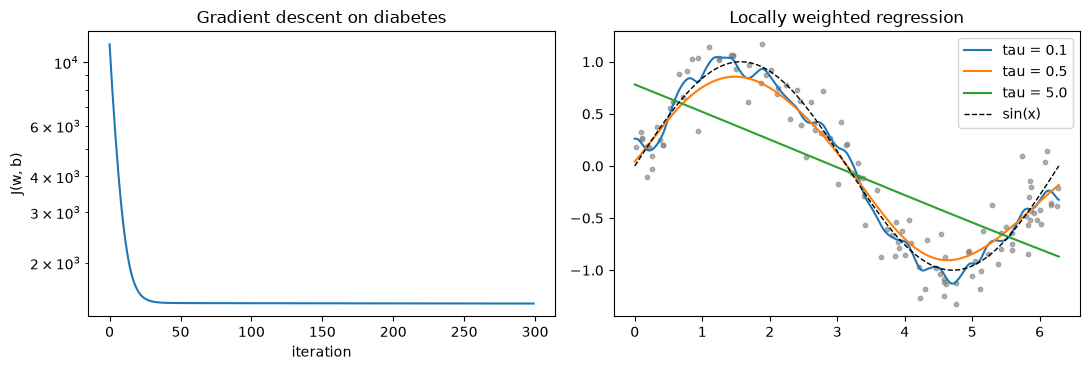

In [3]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 2 * np.pi, 120))
y_sin = np.sin(x) + 0.2 * rng.normal(size=x.size)
grid = np.linspace(0, 2 * np.pi, 300)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(gd.loss_history[:300])
ax[0].set(title="Gradient descent on diabetes", xlabel="iteration", ylabel="J(w, b)", yscale="log")
ax[1].scatter(x, y_sin, s=10, c="gray", alpha=0.6)
for tau in [0.1, 0.5, 5.0]:
    ax[1].plot(grid, ms.LocallyWeightedRegression(tau).fit(x, y_sin).predict(grid), label=f"tau = {tau}")
ax[1].plot(grid, np.sin(grid), "k--", lw=1, label="sin(x)")
ax[1].set(title="Locally weighted regression")
ax[1].legend()
plt.tight_layout()

for tau in [0.1, 0.5, 5.0]:
    err = rmse(np.sin(grid), ms.LocallyWeightedRegression(tau).fit(x, y_sin).predict(grid))
    print(f"tau = {tau:<4} RMSE vs true curve: {err:.3f}")

## Logistic regression

Breast cancer dataset (569 tumours, 30 features). `l2 = 1 / (C n)` gives the same objective as
scikit-learn's `LogisticRegression(C=C)`; both are run to a tight tolerance.

In [4]:
X, y = datasets.load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=0)
Xtr, Xte = standardize(Xtr, Xte)
C = 1.0

lr, t1 = timed(lambda: ms.LogisticRegression(l2=1 / (C * len(ytr)), n_iters=20000).fit(Xtr, ytr))
sk, t2 = timed(lambda: linear_model.LogisticRegression(C=C, tol=1e-8, max_iter=5000).fit(Xtr, ytr))
compare("Logistic regression", "test accuracy", accuracy(yte, lr.predict(Xte)), accuracy(yte, sk.predict(Xte)), t1, t2)
print("max |P_ours - P_sklearn| on test set:", f"{np.abs(lr.predict_proba(Xte) - sk.predict_proba(Xte)).max():.1e}")

Logistic regression      test accuracy: ours 0.9912  sklearn 0.9912   fit ms: ours 98.92  sklearn 1.63
max |P_ours - P_sklearn| on test set: 8.5e-06


## k-means and PCA

k-means on four Gaussian blobs; PCA projects the 64-pixel digits onto two components.

k-means (k=4)            inertia: ours 1205.1708  sklearn 1205.1708   fit ms: ours 3.04  sklearn 3.59
adjusted Rand index vs true blobs: ours 1.0000, sklearn 1.0000
PCA (2 of 64)            explained var.: ours 0.2851  sklearn 0.2851   fit ms: ours 3.24  sklearn 0.38


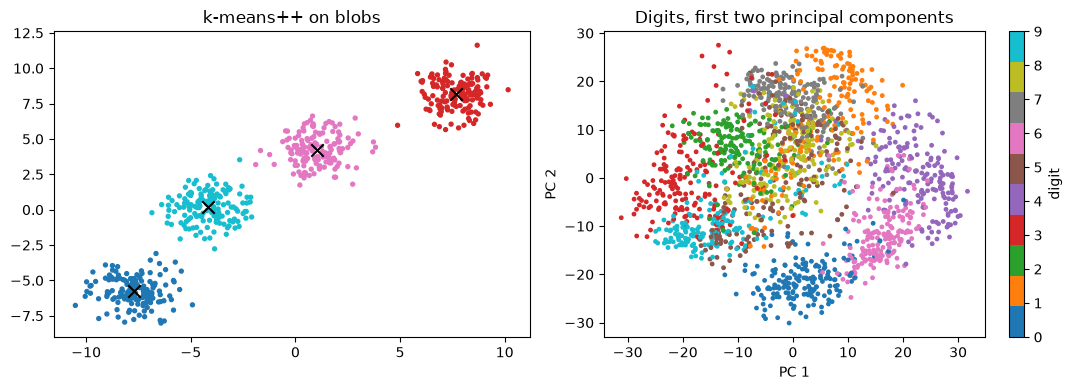

In [5]:
Xb, yb = datasets.make_blobs(n_samples=600, centers=4, cluster_std=1.0, random_state=3)
km, t1 = timed(lambda: ms.KMeans(n_clusters=4).fit(Xb))
skm, t2 = timed(lambda: cluster.KMeans(n_clusters=4, n_init=10, random_state=0).fit(Xb))
compare("k-means (k=4)", "inertia", km.inertia_, skm.inertia_, t1, t2)
print(f"adjusted Rand index vs true blobs: ours {adjusted_rand_score(yb, km.labels_):.4f}, "
      f"sklearn {adjusted_rand_score(yb, skm.labels_):.4f}")

Xd, yd = datasets.load_digits(return_X_y=True)
pca, t1 = timed(lambda: ms.PCA(2).fit(Xd))
skp, t2 = timed(lambda: decomposition.PCA(2).fit(Xd))
compare("PCA (2 of 64)", "explained var.", pca.explained_variance_ratio_.sum(), skp.explained_variance_ratio_.sum(), t1, t2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(*Xb.T, c=km.labels_, s=8, cmap="tab10")
ax[0].scatter(*km.centers.T, c="k", marker="x", s=80)
ax[0].set(title="k-means++ on blobs")
Z = pca.transform(Xd)
sc = ax[1].scatter(*Z.T, c=yd, s=6, cmap="tab10")
ax[1].set(title="Digits, first two principal components", xlabel="PC 1", ylabel="PC 2")
fig.colorbar(sc, ax=ax[1], label="digit")
plt.tight_layout()

## Decision trees

CART with Gini impurity (wine, 3 classes) and squared error (diabetes).

In [6]:
X, y = datasets.load_wine(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=0)
dt, t1 = timed(lambda: ms.DecisionTreeClassifier(max_depth=4).fit(Xtr, ytr))
sk, t2 = timed(lambda: tree.DecisionTreeClassifier(max_depth=4, random_state=0).fit(Xtr, ytr))
compare("Tree classifier (d=4)", "test accuracy", accuracy(yte, dt.predict(Xte)), accuracy(yte, sk.predict(Xte)), t1, t2)

X, y = datasets.load_diabetes(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=0)
dr, t1 = timed(lambda: ms.DecisionTreeRegressor(max_depth=4, min_samples_leaf=5).fit(Xtr, ytr))
sk, t2 = timed(lambda: tree.DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=0).fit(Xtr, ytr))
compare("Tree regressor (d=4)", "test RMSE", rmse(yte, dr.predict(Xte)), rmse(yte, sk.predict(Xte)), t1, t2)

Tree classifier (d=4)    test accuracy: ours 0.8889  sklearn 0.8889   fit ms: ours 2.16  sklearn 0.33


Tree regressor (d=4)     test RMSE: ours 61.4789  sklearn 61.4789   fit ms: ours 1.91  sklearn 0.35


## Summary

In [7]:
print(f"{'model':<24} {'metric':<15} {'ours':>9} {'sklearn':>9} {'ours ms':>9} {'sk ms':>8}")
for name, metric, a, b, ta, tb in results:
    print(f"{name:<24} {metric:<15} {a:>9.4f} {b:>9.4f} {ta:>9.2f} {tb:>8.2f}")

model                    metric               ours   sklearn   ours ms    sk ms
Linear (grad. descent)   test RMSE         53.2601   53.2601    212.23     0.17
Linear (normal eq.)      test RMSE         53.2601   53.2601      0.05     0.17
Ridge (alpha=10)         test RMSE         53.1368   53.1368      0.03     0.16
Logistic regression      test accuracy      0.9912    0.9912     98.92     1.63
k-means (k=4)            inertia         1205.1708 1205.1708      3.04     3.59
PCA (2 of 64)            explained var.     0.2851    0.2851      3.24     0.38
Tree classifier (d=4)    test accuracy      0.8889    0.8889      2.16     0.33
Tree regressor (d=4)     test RMSE         61.4789   61.4789      1.91     0.35
